# Predict with all EpiHydra clocks at once

Builds one `MultiClockPredictor`: the frozen, LoRA-merged backbone from `best_model.pt` with one head per clock.

- `"age"` (always included) uses the head stored in `best_model.pt`.
- Every other clock uses `best_head_<clock>.pt` from `HEAD_PATH`.

Each batch goes through the backbone **once** and the hidden states fan out to every head. The output is a table of predictions (plus true labels where available) with one row per sample. Metrics come later.

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path

# ── Which clocks to predict ──────────────────────────────────────
# None = "age" + every best_head_<clock>.pt found in HEAD_PATH.
# Or give a list, e.g. ["age", "horvath_age", "phenoage_age"]; "age" is always added first.
CLOCKS     = None
EVAL_SPLIT = "all"    # "train", "valid", "test" or "all"

# ── Paths ────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/combined/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"   # MethylGPT backbone + vocab + args.json
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks4_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261105_072540"
LORA_CKPT     = EPIHYDRA_PATH / "best_model.pt"           # LoRA backbone + the "age" head

# ── Model settings (must match training) ─────────────────────────
NUM_HEADS  = 4
LORA_R     = 16
LORA_ALPHA = 8

# ── Data split (must match training so the test set is truly held out) ──
SPLIT_RATIOS = dict(train_ratio=0.5, valid_ratio=0.25, test_ratio=0.25)
BATCH_SIZE   = 8
RANDOM_STATE = 42

# Where to save the prediction table (None = don't save)
OUT_CSV = None

## Imports

In [2]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import pandas as pd
import torch

# eval_utils also adds ../04_epihydra to sys.path, so import it first
from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
import eval_utils as eu
from epihydra import VocabWrapper
from train import build_multiclock_dataloaders

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clock_names = eu.resolve_clocks(CLOCKS, HEAD_PATH)

print(f"Using device : {device}")
print(f"Clocks       : {clock_names}")
print(f"Split        : {EVAL_SPLIT}")

Using device : cuda
Clocks       : ['age', 'grimageadapter_age', 'hannum_age', 'horvath_age', 'phenoage_age']
Split        : all


## Load data, config and vocab

In [3]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

# MethylGPT pre-training config (layer sizes, number of CpGs, ...)
with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

# CpG vocabulary used for tokenisation
vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
One dataset carries every clock's label. Samples are kept if they have a label for at least one clock, so missing labels show up as NaN in the `_true` columns.

The saved training scalers from `HEAD_PATH/scalers.pkl` are passed in and reused. Any clock without a saved scaler (i.e. `"age"`) gets one fitted on this training split.

In [4]:
saved_scalers = eu.load_saved_scalers(HEAD_PATH)

splits = build_multiclock_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_names  = clock_names,
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scalers      = saved_scalers,   # reused where available, fitted otherwise
    **SPLIT_RATIOS,
)
scalers = splits["scalers"]         # the scalers actually used, one per clock

Samples in meta : 1743
Samples in CpG  : 1743
Common samples  : 1743
Samples after drop : 1743
  age                 : 1743 labeled
  grimageadapter_age  : 1743 labeled
  hannum_age          : 1743 labeled
  horvath_age         : 1743 labeled
  phenoage_age        : 1743 labeled

Vocab CpGs : 49,159 | Present : 49,156 (100.0%) | Missing : 3

Train : 871 | Valid : 436 | Test : 436
ℹ  age                 : scaler fitted on training values.
ℹ  grimageadapter_age  : reusing supplied pre-fitted scaler.
ℹ  hannum_age          : reusing supplied pre-fitted scaler.
ℹ  horvath_age         : reusing supplied pre-fitted scaler.
ℹ  phenoage_age        : reusing supplied pre-fitted scaler.
✓ Multi-clock data loaded and ready.



## Build the multi-clock model
Rebuilds the backbone the heads were trained on (LoRA adapters loaded from `best_model.pt`, merged and frozen), then loads one head per clock.

In [5]:
model = eu.build_multiclock_model(
    MODEL_PATH, vocab, pretrain_config,
    lora_ckpt   = LORA_CKPT,
    head_path   = HEAD_PATH,
    clock_names = clock_names,
    device      = device,
    num_heads   = NUM_HEADS,
    lora_r      = LORA_R,
    lora_alpha  = LORA_ALPHA,
)

I0000 00:00:1793867960.179567  934892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793867960.212309  934892 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793867962.039868  934892 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: U

Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt

Loading frozen LoRA adapters from /work/gr-fe/bryan/EpiHydra/results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750/best_model.pt
  source run   : nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750
  source epoch : 85  (valid MAE 4.864)
  lora_r=16 lora_alpha=8 targets=['Wqkv', 'out_proj', 'linear1', 'linear2']
  adapter tensors in checkpoint : 52
  adapter tensors in model      : 52 (lora_A + lora_B pairs)
  lora_B with non-zero weights  : 26/26
  adapters merged into base weights

  loaded head age                  <- best_model.pt
  loaded head grimageadapter_age   <- best_head_grimageadapter_age.pt (epoch 46)
  loaded head hannum_age           <- best_head_hannum_age.pt (epoch 47)
  loaded head horvath_age          <- best_head_horvath_age.pt (epoch 31)
  loaded head phenoage_age         <- best_head_phenoage_age.p

## Predict
One forward pass through the backbone per batch, shared across all heads. Loaders are rebuilt unshuffled so each row lines up with its sample ID.

In [6]:
split_names = ["train", "valid", "test"] if EVAL_SPLIT == "all" else [EVAL_SPLIT]

tables = []
for split in split_names:
    loader = eu.ordered_loader(splits[f"{split}_loader"])
    ids    = splits[f"{split}_df"].index
    table  = eu.predict_multiclock(model, loader, scalers, device, clock_names, ids)
    table.insert(0, "split", split)
    tables.append(table)

predictions = pd.concat(tables)
print(f"{len(predictions)} samples x {len(clock_names)} clocks")

1743 samples x 5 clocks


## Prediction table

In [7]:
pred_cols = [f"{c}_pred" for c in clock_names]

# Predictions only (one column per clock)
display(predictions[["split"] + pred_cols].round(2))

,split,age_pred,grimageadapter_age_pred,hannum_age_pred,horvath_age_pred,phenoage_age_pred
ID,,,,,,
GSM1051529,train,41.680000,55.410000,49.650002,40.889999,32.459999
GSM990094,train,63.369999,73.790001,69.989998,62.779999,58.340000
GSM667383,train,7.640000,98.519997,65.230003,9.170000,-12.660000
GSM1052186,train,49.200001,62.470001,55.259998,46.599998,43.480000
GSM666992,train,8.820000,100.269997,66.730003,9.520000,-11.580000
...,...,...,...,...,...,...
GSM1051976,test,47.299999,60.549999,53.009998,44.939999,43.070000
GSM990596,test,60.950001,71.300003,66.419998,60.040001,53.750000
GSM1052124,test,52.669998,66.949997,59.430000,49.369999,47.930000


In [10]:
# Full table: predicted and true values side by side, per clock
display(predictions)

if OUT_CSV is not None:
    predictions.to_csv(OUT_CSV)
    print(f"Saved to {OUT_CSV}")

,split,age_pred,age_true,grimageadapter_age_pred,grimageadapter_age_true,hannum_age_pred,hannum_age_true,horvath_age_pred,horvath_age_true,phenoage_age_pred,phenoage_age_true
ID,,,,,,,,,,,
GSM1051529,train,41.684082,33.000,55.410278,44.952442,49.652248,42.880848,40.886246,36.141735,32.458595,32.540615
GSM990094,train,63.374580,60.000,73.789711,71.671951,69.993332,70.433876,62.775871,58.382236,58.337753,54.767109
GSM667383,train,7.644023,5.917,98.515083,98.954811,65.229790,65.671150,9.165030,7.283458,-12.658775,-11.887487
GSM1052186,train,49.199646,28.000,62.469444,50.127384,55.260933,43.789944,46.595627,39.617607,43.481201,36.685280
GSM666992,train,8.815358,6.417,100.270729,98.979111,66.728004,67.447632,9.517734,12.610179,-11.580477,-10.425083
...,...,...,...,...,...,...,...,...,...,...,...
GSM1051976,test,47.296974,42.000,60.549206,62.256466,53.013618,52.485893,44.942329,47.350689,43.070419,44.621891
GSM990596,test,60.948669,66.000,71.302544,68.147552,66.420677,66.841942,60.042423,63.869198,53.750710,55.050472
GSM1052124,test,52.672031,42.000,66.950005,56.729572,59.429031,51.091846,49.373161,43.120762,47.931320,39.103073


In [ ]:
def cross_clock_metrics(predictions, clock_names, min_samples=2):
    """
    Compare every clock's predictions against every clock's true values.
 
    For each (pred clock i, true clock j) pair, uses all rows where both
    `<i>_pred` and `<j>_true` are non-NaN (pairwise, so a missing label for
    one clock doesn't drop that sample from other pairs).
 
    Parameters
    ----------
    predictions : DataFrame from predict_multiclock (or several concatenated),
                  with '<clock>_pred' and '<clock>_true' columns
    clock_names : list[str]
    min_samples : int — pairs with fewer usable samples are left as NaN
 
    Returns
    -------
    dict of three n×n DataFrames, keyed 'pearson_r', 'mae', 'r2'.
    Rows = predicted clock, columns = true clock, so the diagonal is each
    clock scored against its own labels. R² is r2_score(true, pred) and is
    not symmetric.
    """
    import pandas as pd
 
    names = list(clock_names)
    out = {m: pd.DataFrame(np.nan, index=pd.Index(names, name="pred"),
                           columns=pd.Index(names, name="true"))
           for m in ("pearson_r", "mae", "r2")}
 
    for p in names:
        for t in names:
            pair = predictions[[f"{p}_pred", f"{t}_true"]].dropna()
            if len(pair) < min_samples:
                continue
            pred, true = pair.iloc[:, 0].to_numpy(), pair.iloc[:, 1].to_numpy()
 
            out["mae"].loc[p, t] = np.mean(np.abs(pred - true))
            # r and R² are undefined if either side is constant
            if np.std(pred) > 0 and np.std(true) > 0:
                out["pearson_r"].loc[p, t] = pearsonr(true, pred)[0]
                out["r2"].loc[p, t] = r2_score(true, pred)
    return out

In [19]:
cross = cross_clock_metrics(predictions, clock_names)

for metric, table in cross.items():
    display(style_cross_clock(table, metric))

true,age,grimageadapter_age,hannum_age,horvath_age,phenoage_age
pred,,,,,
age,0.969,-0.422,0.366,0.972,0.955
grimageadapter_age,-0.457,0.937,0.565,-0.488,-0.576
hannum_age,0.366,0.612,0.921,0.338,0.226
horvath_age,0.969,-0.436,0.354,0.977,0.961
phenoage_age,0.956,-0.519,0.252,0.967,0.975


true,age,grimageadapter_age,hannum_age,horvath_age,phenoage_age
pred,,,,,
age,4.739,30.200,18.770,4.151,9.222
grimageadapter_age,29.556,4.126,12.415,29.480,37.787
hannum_age,18.483,12.774,3.153,18.011,26.163
horvath_age,4.723,29.617,18.169,3.605,9.568
phenoage_age,10.103,38.220,26.602,9.616,4.944


true,age,grimageadapter_age,hannum_age,horvath_age,phenoage_age
pred,,,,,
age,0.937,-6.277,-5.179,0.939,0.815
grimageadapter_age,-2.548,0.877,-1.445,-3.026,-2.748
hannum_age,-0.404,-0.123,0.848,-0.549,-0.812
horvath_age,0.936,-6.010,-4.821,0.955,0.802
phenoage_age,0.733,-9.723,-10.147,0.694,0.950


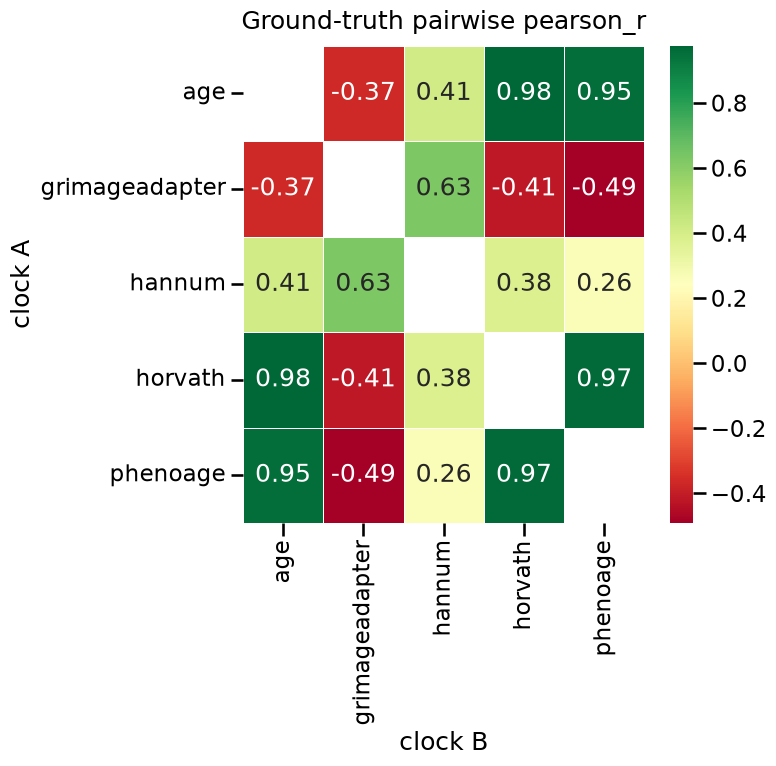

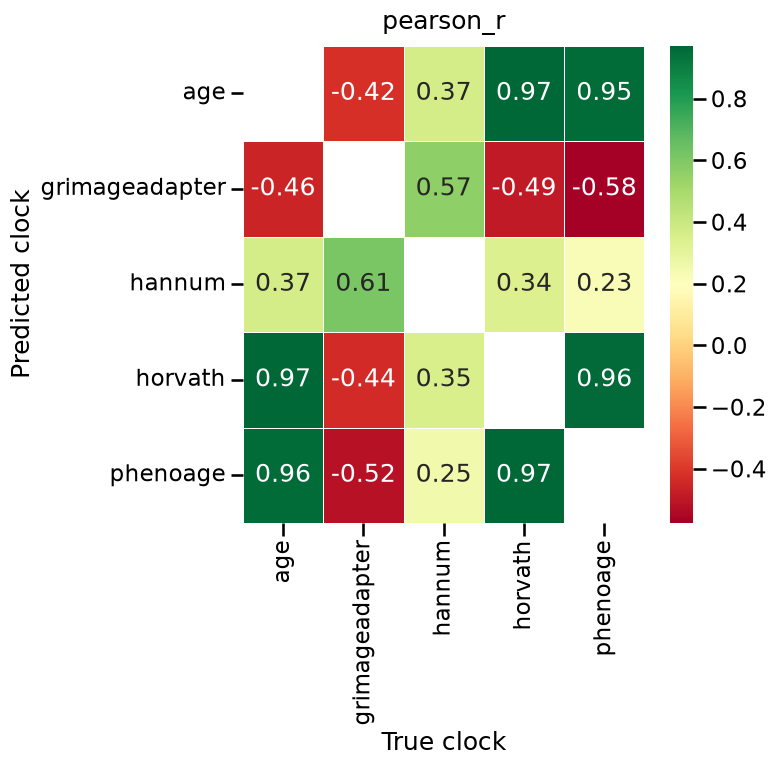

In [52]:
fig_true  = plot_true_clock_heatmap(predictions, clock_names, metric="pearson_r")
fig_cross = plot_cross_clock_heatmap(cross, "pearson_r")

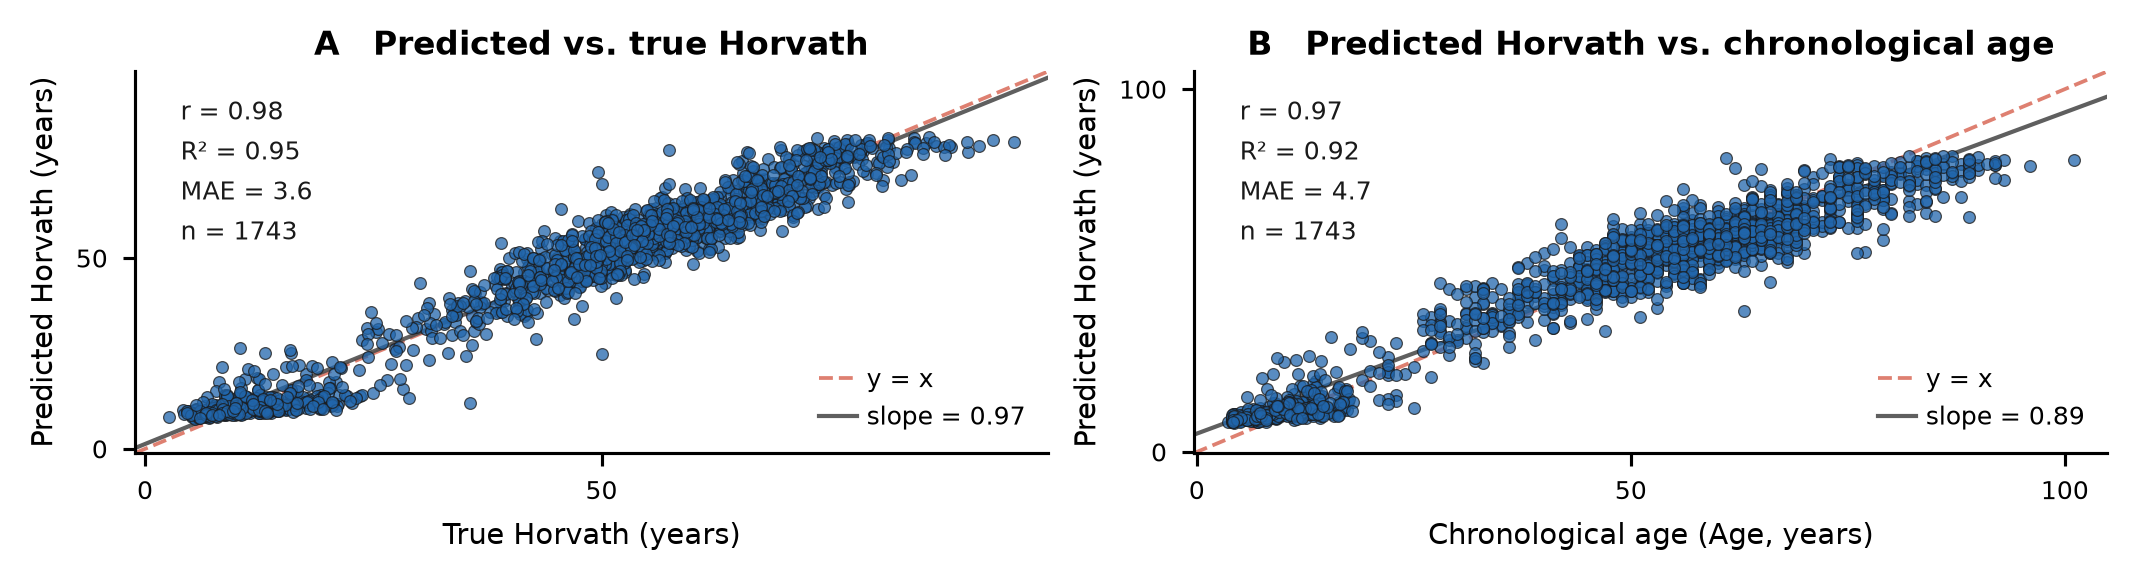

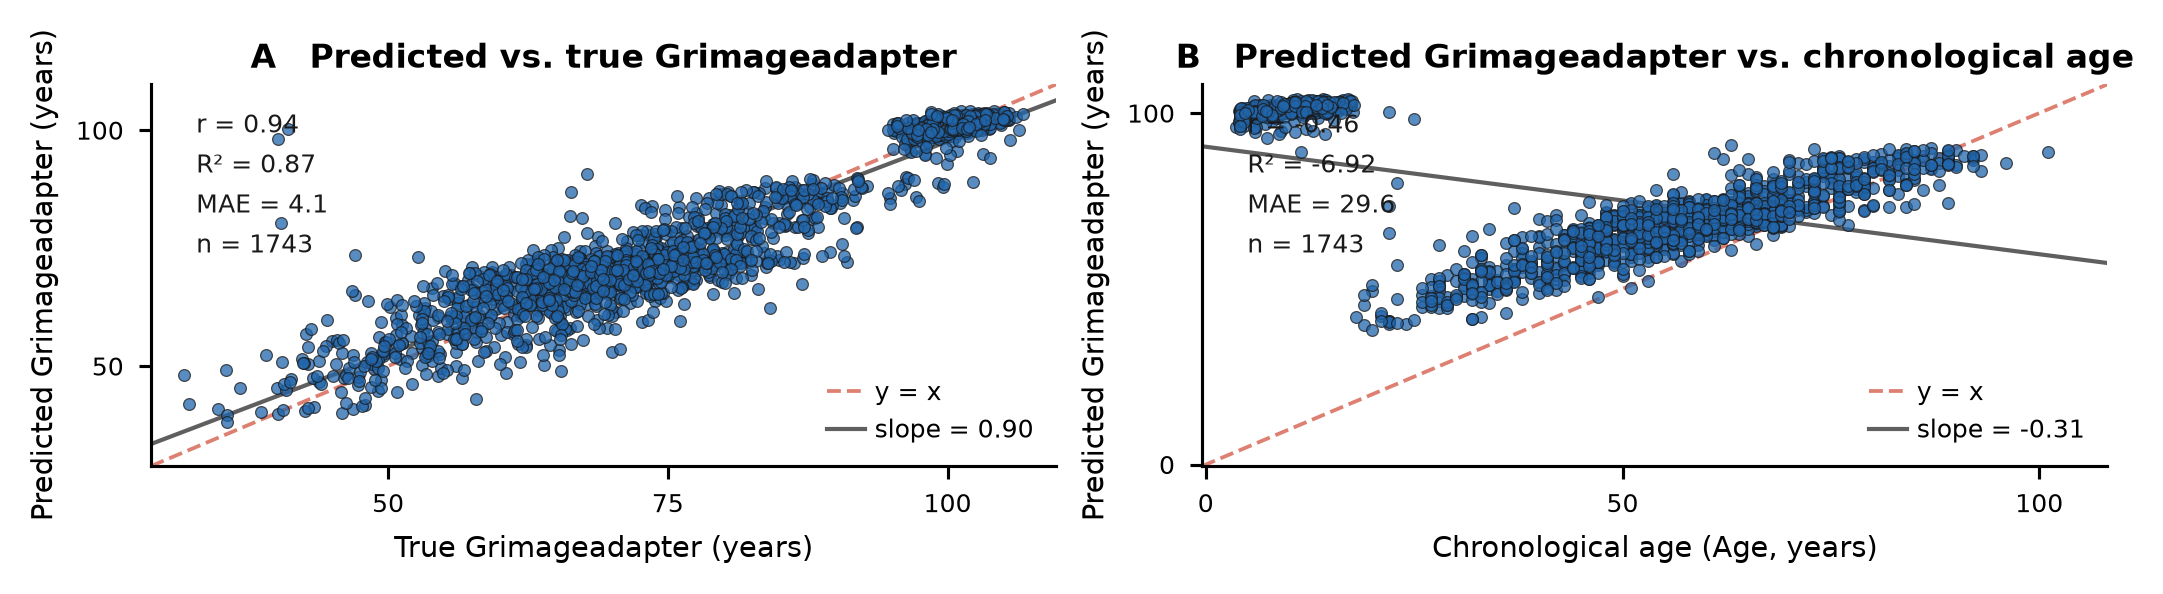

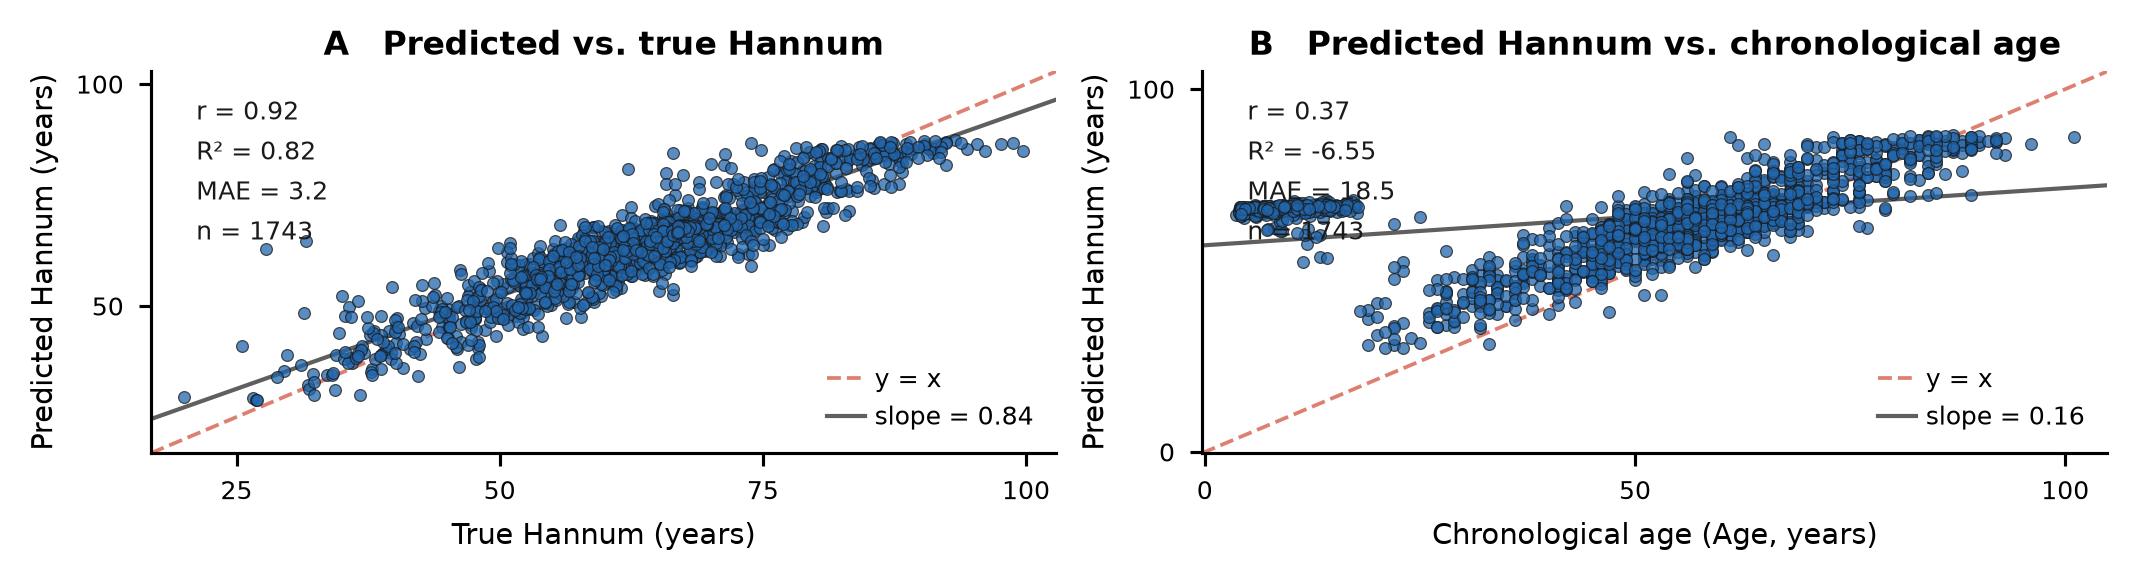

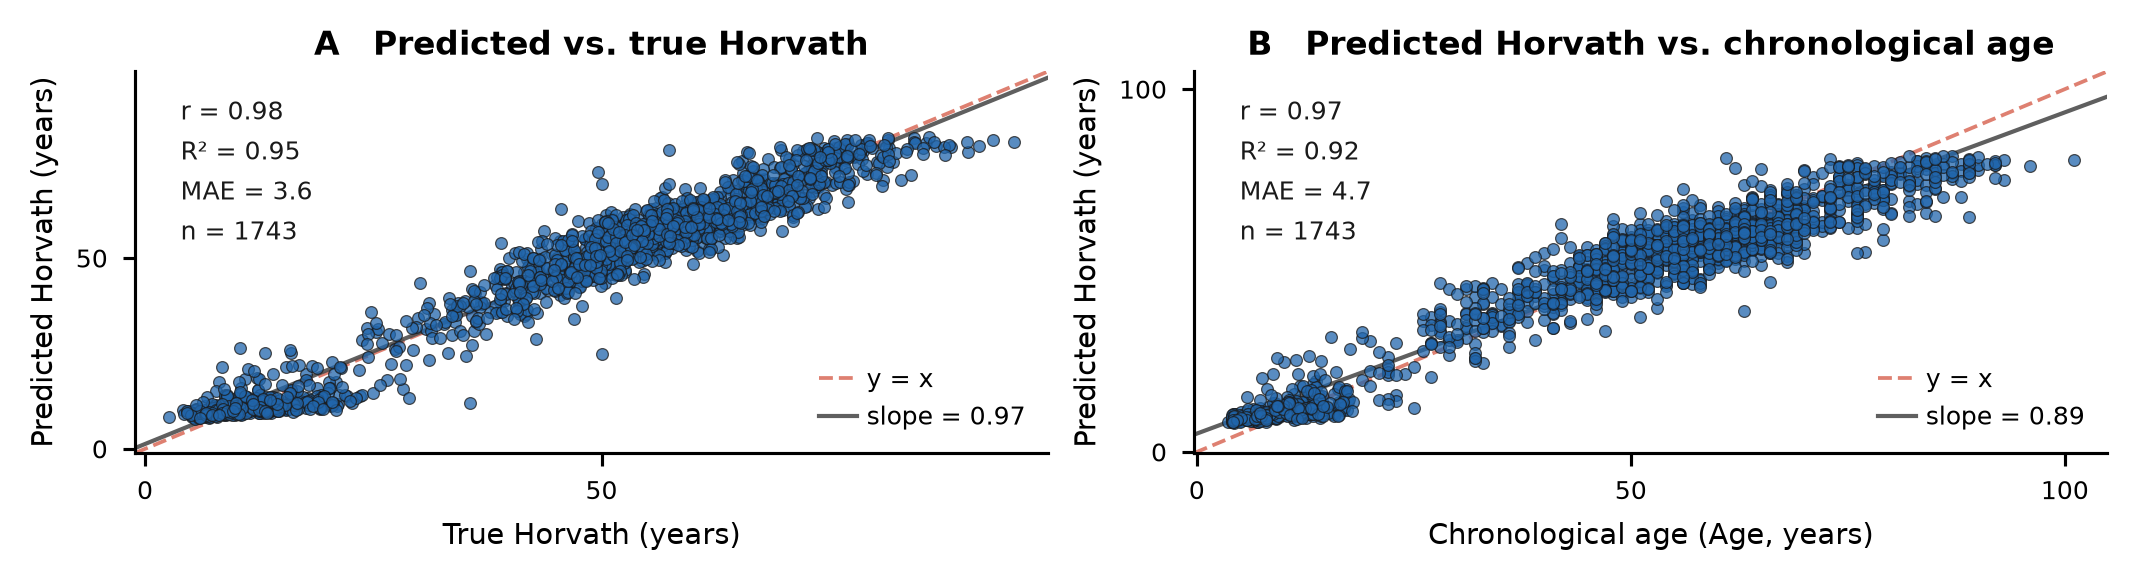

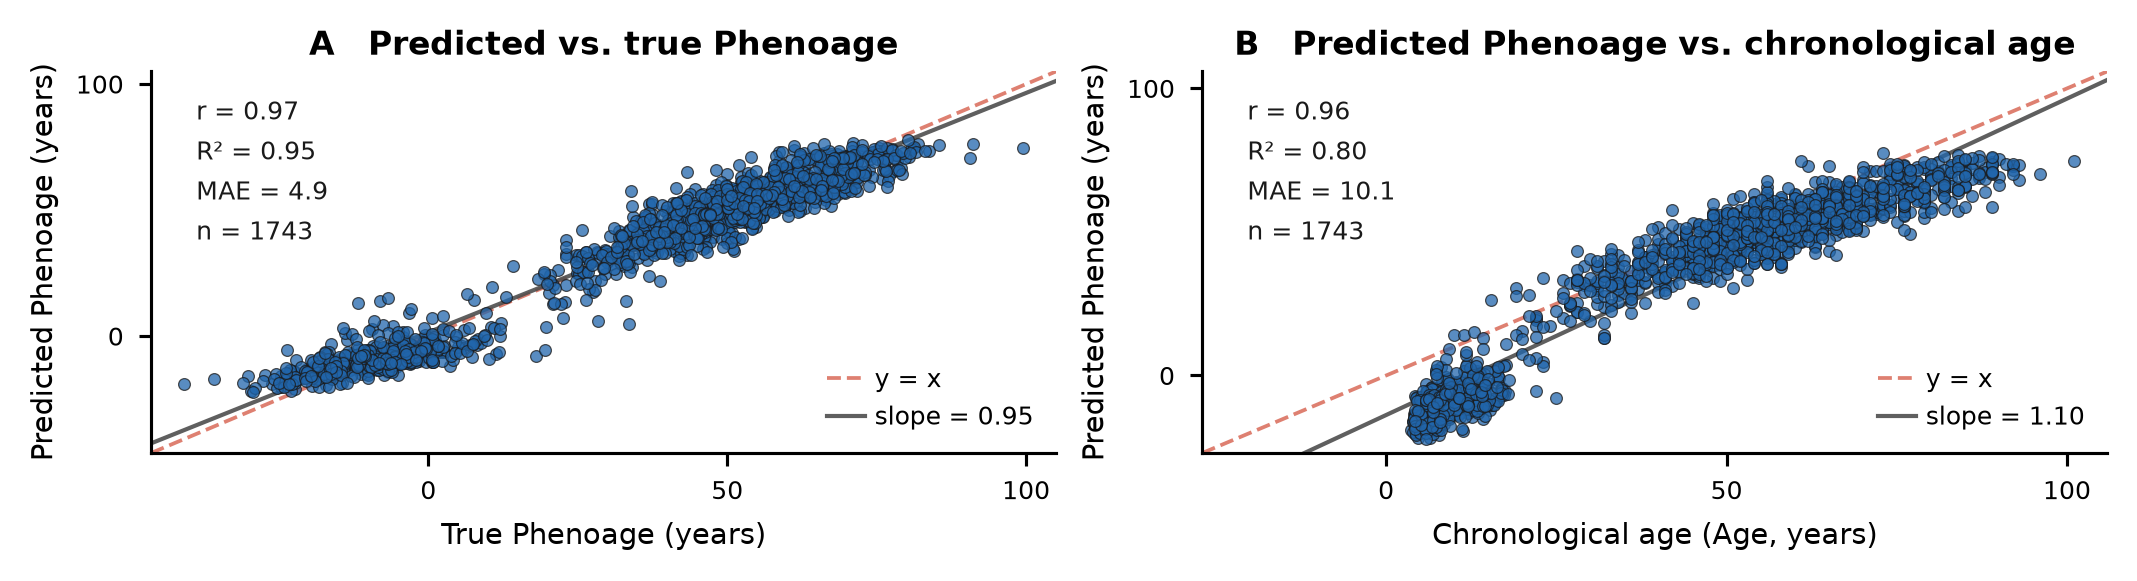

In [62]:
# One clock at a time
fig, (ax_a, ax_b), stats = plot_clock_panels(
    predictions, "horvath_age",
    chron_clock  = "age",          # column to use as chronological age
    save_path    = None,   # saves .pdf + .png, or None
    fig_width_mm = 89,             # NM single-column width
)

# All clocks at once (skips chron_clock itself)
results = plot_all_clock_panels(predictions, clock_names,
                                   chron_clock="age", save_dir=None)